# 02 – Phân tích khám phá (EDA)

Đầu vào: `data/processed/stores_clean.csv` (3.208 cửa hàng sau tiền xử lý).

Nội dung:
1. Phân phối category, loại hình, **nhóm loại hình chính** (biến mục tiêu của notebook 05)
2. Phân bố theo phường, theo tuyến đường
3. Rating: phân phối, theo nhóm loại hình, theo phường
4. Chuỗi (chain) và cửa hàng độc lập
5. Bảng chéo phường × nhóm loại hình
6. Bản đồ: điểm theo category + HeatMap mật độ
7. Nhận xét

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import folium

from src import cleaning as cl, geo, features as ft, viz

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
viz.set_style()
PROC = ROOT / "data" / "processed"
TABLES = viz.TABLE_DIR

from scipy import stats

df = pd.read_csv(PROC / "stores_clean.csv")
df["type_group"] = [ft.primary_group(t, c) for t, c in zip(df["product_types"], df["category"])]
df["street"] = df["address"].map(cl.street_of)
df["ward_hc"] = df["ward_final"].where(df["ward_final"] != "Ngoài Hải Châu")  # chỉ 13 phường Hải Châu
print(df.shape)

(3208, 50)


## 1. Category và loại hình

**Nhóm loại hình chính (`type_group`)** được xác định như sau:
- Lấy nhãn đầu tiên trong danh sách loại hình mà không phải "Others"/"Healthy Food", rồi ánh xạ về 1 trong 9 nhóm (xem `ft.LABEL_TO_GROUP`).
- Cửa hàng SHOP luôn thuộc nhóm "Cửa hàng thực phẩm".
- Cửa hàng chỉ có nhãn chung chung thuộc nhóm "Khác".

In [2]:
cat = df["category"].value_counts()
print((cat.to_frame("n").assign(pct=lambda d: (d["n"] / d["n"].sum() * 100).round(1))).to_string())
print(f"Tỉ lệ mất cân bằng FOOD:SHOP ≈ {cat['FOOD'] / cat['SHOP']:.1f}:1")

grp = df["type_group"].value_counts()
grp_tbl = grp.to_frame("n").assign(pct=lambda d: (d["n"] / d["n"].sum() * 100).round(1))
grp_tbl

             n   pct
category            
FOOD      2976  92.8
SHOP       232   7.2
Tỉ lệ mất cân bằng FOOD:SHOP ≈ 12.8:1


,n,pct
type_group,,
Cà phê & nước,687,21.4
Bún/Phở/Cháo,588,18.3
Ăn vặt & Bánh mì,492,15.3
Cơm,340,10.6
Lẩu & Nướng,234,7.3
Cửa hàng thực phẩm,232,7.2
Fast food & Quốc tế,221,6.9
Trà sữa,216,6.7
Tráng miệng,120,3.7


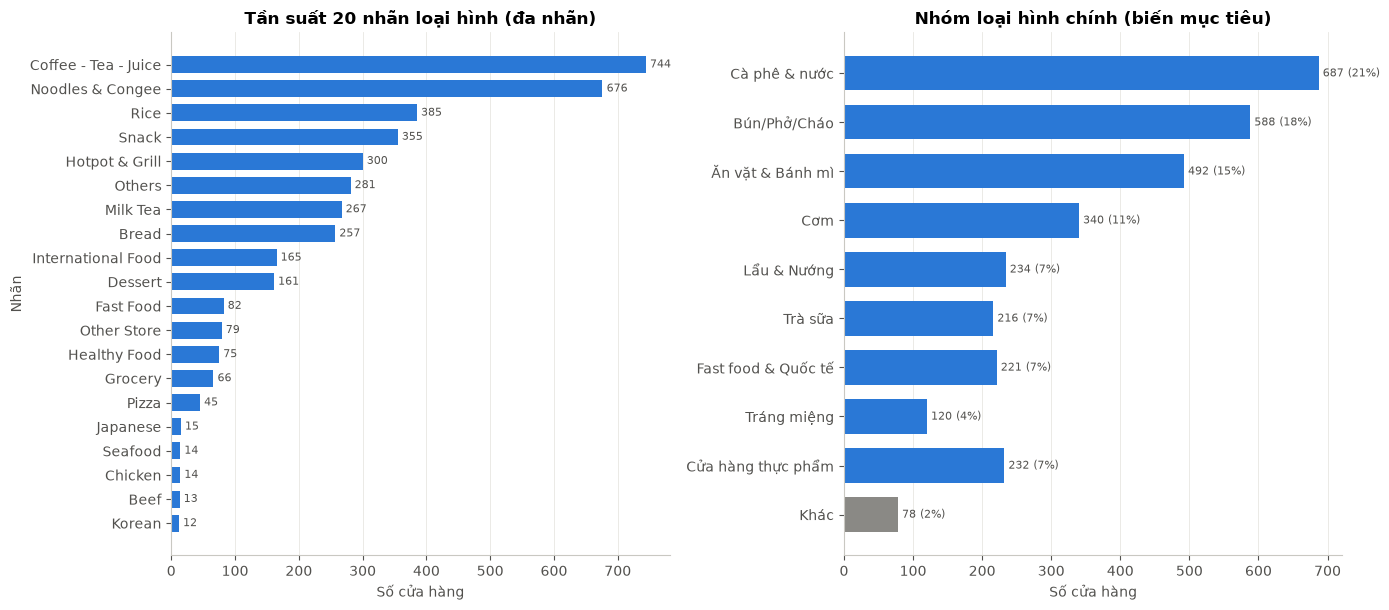

In [3]:
labels = df["product_types"].str.split("|").explode().value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
viz.barh_counts(labels, "Tần suất 20 nhãn loại hình (đa nhãn)", "Số cửa hàng", "Nhãn", ax=axes[0])
order = [g for g in ft.GROUP_ORDER + [ft.OTHER_GROUP] if g in grp.index]
colors = [viz.GRAY if g == ft.OTHER_GROUP else viz.PALETTE[0] for g in order]
s = grp.reindex(order).iloc[::-1]
bars = axes[1].barh(s.index, s.values, color=colors[::-1], height=0.7)
axes[1].bar_label(bars, labels=[f"{v} ({v / len(df):.0%})" for v in s.values], padding=3, fontsize=8, color=viz.TEXT_2)
axes[1].set_title("Nhóm loại hình chính (biến mục tiêu)")
axes[1].set_xlabel("Số cửa hàng"); axes[1].set_ylabel(""); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); viz.save_fig(fig, "02_type_distribution"); plt.show()

In [4]:
print("Số nhãn / cửa hàng:")
print(df["n_types"].value_counts().sort_index().to_string())
print(f"Tỉ lệ cửa hàng đa nhãn: {(df['n_types'] > 1).mean():.1%}")

Số nhãn / cửa hàng:
n_types
1    2617
2     425
3     132
4      27
5       7
Tỉ lệ cửa hàng đa nhãn: 18.4%


## 2. Phân bố theo phường và tuyến đường

Phường dùng `ward_final`, tức ưu tiên phường ghi trong địa chỉ (lý do xem notebook 01, mục 4). Nhóm "Ngoài Hải Châu" gồm các điểm sát ranh giới và được tách riêng.

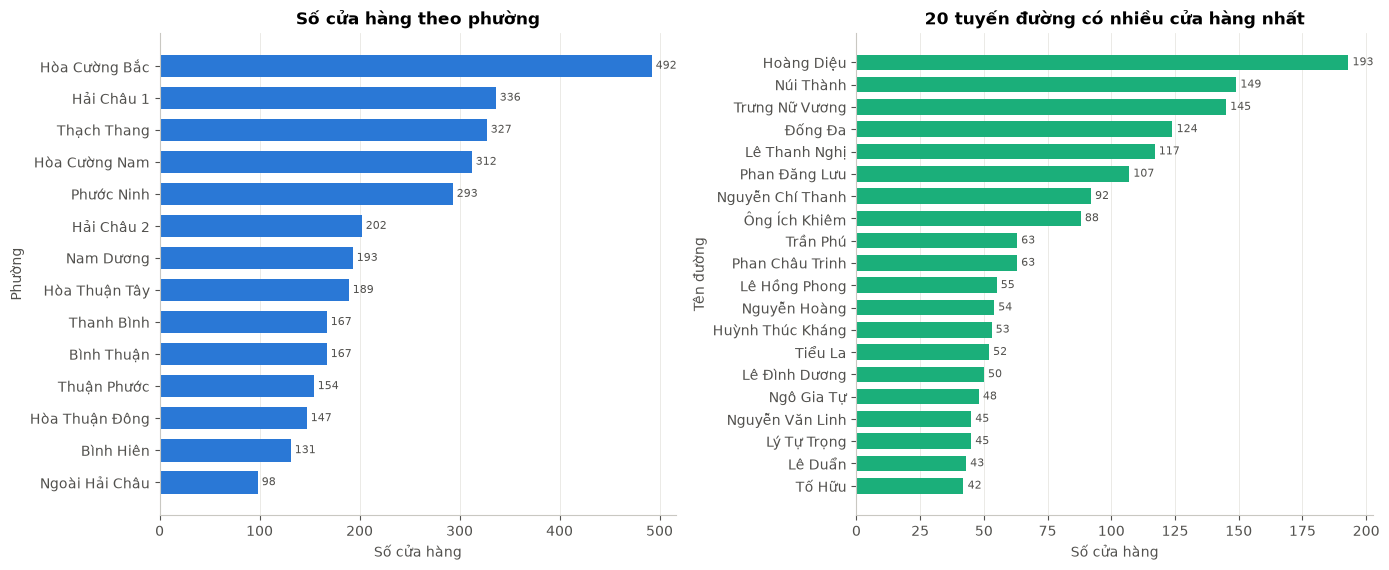

Số tuyến đường khác nhau: 318 | top 10 tuyến chiếm 37.4% số cửa hàng có tên đường


In [5]:
ward_cnt = df["ward_final"].value_counts()
street_cnt = df["street"].value_counts().head(20)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.8))
viz.barh_counts(ward_cnt, "Số cửa hàng theo phường", "Số cửa hàng", "Phường", ax=axes[0])
viz.barh_counts(street_cnt, "20 tuyến đường có nhiều cửa hàng nhất", "Số cửa hàng", "Tên đường", ax=axes[1],
                color=viz.PALETTE[2])
fig.tight_layout(); viz.save_fig(fig, "02_ward_street_counts"); plt.show()
print(f"Số tuyến đường khác nhau: {df['street'].nunique()} | top 10 tuyến chiếm "
      f"{df['street'].value_counts().head(10).sum() / df['street'].notna().sum():.1%} số cửa hàng có tên đường")

## 3. Rating

Nhắc lại **giả định** từ notebook 01: `rating = flag/10`, và chỉ xét các cửa hàng có `has_rating = True`.

In [6]:
rated = df[df["has_rating"]]
print(f"Có rating: {len(rated)} / {len(df)} ({len(rated) / len(df):.1%}) | rating TB = {rated['rating'].mean():.2f}, "
      f"trung vị = {rated['rating'].median():.1f}")

def rating_table(by):
    t = df.groupby(by).agg(n=("storeId", "size"), pct_rated=("has_rating", "mean"),
                           mean_rating=("rating", "mean"), median_rating=("rating", "median"))
    t["pct_rated"] = (t["pct_rated"] * 100).round(1)
    return t.round(2).sort_values("mean_rating", ascending=False)

rt_type = rating_table("type_group")
rt_ward = rating_table("ward_final")
rt_type

Có rating: 1661 / 3208 (51.8%) | rating TB = 4.12, trung vị = 4.0


,n,pct_rated,mean_rating,median_rating
type_group,,,,
Lẩu & Nướng,234,65.0,4.25,4.4
Cà phê & nước,687,55.6,4.16,4.0
Tráng miệng,120,60.0,4.15,4.2
Bún/Phở/Cháo,588,50.0,4.12,4.0
Trà sữa,216,54.2,4.12,4.0
Khác,78,46.2,4.11,4.1
Fast food & Quốc tế,221,53.4,4.11,4.0
Cơm,340,50.6,4.07,4.0
Ăn vặt & Bánh mì,492,54.1,4.07,4.0


In [7]:
rt_ward

,n,pct_rated,mean_rating,median_rating
ward_final,,,,
Hải Châu 1,336,59.8,4.20,4.3
Phước Ninh,293,56.3,4.18,4.3
Bình Hiên,131,48.9,4.15,4.2
Thanh Bình,167,51.5,4.15,4.0
Thạch Thang,327,59.9,4.14,4.0
Nam Dương,193,47.7,4.12,4.0
Thuận Phước,154,51.3,4.12,4.0
Ngoài Hải Châu,98,61.2,4.11,4.0
Hòa Cường Bắc,492,46.1,4.10,4.0


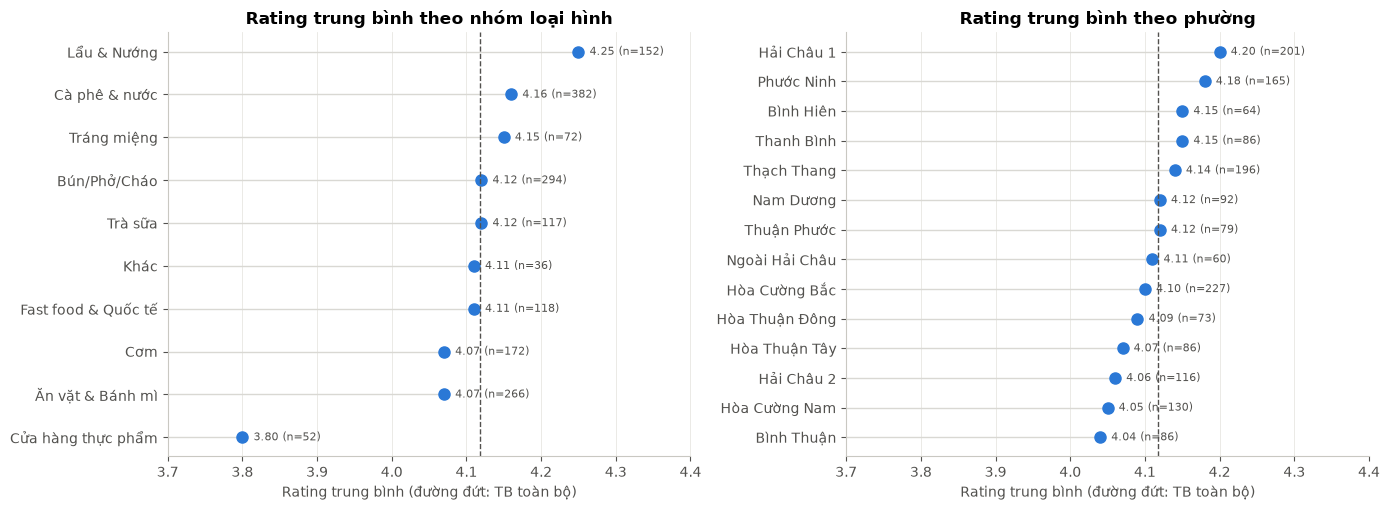

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, t, title in [(axes[0], rt_type, "Rating trung bình theo nhóm loại hình"),
                     (axes[1], rt_ward, "Rating trung bình theo phường")]:
    s = t["mean_rating"].iloc[::-1]
    ax.hlines(s.index, 3.7, s.values, color="#d9d8d3", lw=1)
    ax.plot(s.values, s.index, "o", ms=8, color=viz.PALETTE[0])
    for i, v in s.items():
        ax.annotate(f"{v:.2f} (n={int(round(t.loc[i, 'n'] * t.loc[i, 'pct_rated'] / 100))})", (v, i),
                    xytext=(8, 0), textcoords="offset points", va="center", fontsize=8, color=viz.TEXT_2)
    ax.axvline(rated["rating"].mean(), color=viz.TEXT_2, ls="--", lw=1)
    ax.set_xlim(3.7, 4.4); ax.set_title(title); ax.set_xlabel("Rating trung bình (đường đứt: TB toàn bộ)")
    ax.grid(axis="y", visible=False)
fig.tight_layout(); viz.save_fig(fig, "02_rating_by_type_ward"); plt.show()

In [9]:
# Kiểm định: rating có khác nhau giữa các nhóm loại hình / các phường? (Kruskal–Wallis, phi tham số)
for col in ["type_group", "ward_hc"]:
    groups = [g["rating"].dropna().values for _, g in rated.groupby(col) if g["rating"].notna().sum() >= 10]
    h, p = stats.kruskal(*groups)
    print(f"Kruskal–Wallis theo {col}: H = {h:.1f}, p = {p:.2e}")

Kruskal–Wallis theo type_group: H = 133.8, p = 1.91e-24
Kruskal–Wallis theo ward_hc: H = 47.2, p = 4.23e-06


## 4. Chuỗi (chain) và cửa hàng độc lập

In [10]:
ch = df.groupby("is_chain").agg(n=("storeId", "size"), pct_rated=("has_rating", "mean"),
                                mean_rating=("rating", "mean"))
ch.index = ch.index.map({True: "Chain", False: "Độc lập"})
print(ch.round(3).to_string())
a = rated.loc[rated["is_chain"], "rating"]; b = rated.loc[~rated["is_chain"], "rating"]
u, p = stats.mannwhitneyu(a, b)
print(f"\nMann–Whitney U (rating chain vs độc lập): U = {u:.0f}, p = {p:.3g}")
chain_by_type = pd.crosstab(df["type_group"], df["is_chain"], normalize="index")[True].sort_values(ascending=False)
print("\nTỉ lệ chain theo nhóm loại hình:")
print((chain_by_type * 100).round(1).to_string())

             n  pct_rated  mean_rating
is_chain                              
Độc lập   2503      0.519        4.131
Chain      705      0.513        4.070

Mann–Whitney U (rating chain vs độc lập): U = 202322, p = 3.4e-05

Tỉ lệ chain theo nhóm loại hình:
type_group
Cửa hàng thực phẩm     33.6
Tráng miệng            29.2
Ăn vặt & Bánh mì       24.0
Trà sữa                23.6
Fast food & Quốc tế    23.5
Cơm                    21.2
Cà phê & nước          19.9
Bún/Phở/Cháo           19.0
Khác                   17.9
Lẩu & Nướng            15.4


## 5. Bảng chéo phường × nhóm loại hình

Ta dùng **tỉ lệ theo hàng**, tức cơ cấu loại hình trong từng phường, để so sánh các phường có quy mô khác nhau.

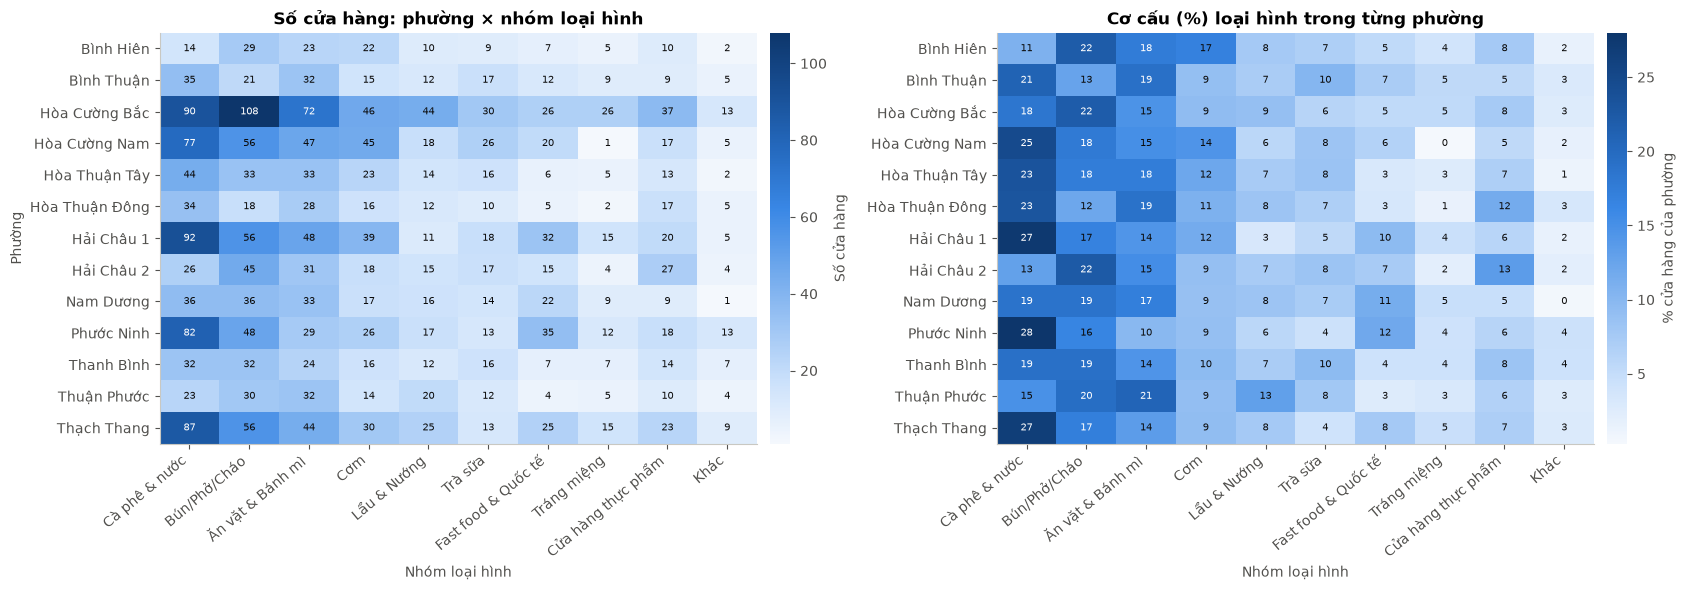

In [11]:
ct = pd.crosstab(df["ward_hc"], df["type_group"]).reindex(columns=ft.GROUP_ORDER + [ft.OTHER_GROUP])
ct_pct = (ct.div(ct.sum(axis=1), axis=0) * 100)
ct.to_csv(TABLES / "02_crosstab_ward_type.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1]})
viz.heatmap(ct, "Số cửa hàng: phường × nhóm loại hình", "Nhóm loại hình", "Phường", ax=axes[0], cbar_label="Số cửa hàng")
viz.heatmap(ct_pct.round(1), "Cơ cấu (%) loại hình trong từng phường", "Nhóm loại hình", "", fmt=".0f",
            ax=axes[1], cbar_label="% cửa hàng của phường")
fig.tight_layout(); viz.save_fig(fig, "02_crosstab_ward_type"); plt.show()

In [12]:
# Phường nào lệch nhiều nhất so với cơ cấu chung? (chênh lệch điểm %)
overall = df.loc[df["ward_hc"].notna(), "type_group"].value_counts(normalize=True) * 100
dev = ct_pct - overall.reindex(ct_pct.columns).values
top_dev = dev.stack().sort_values(key=abs, ascending=False).head(10).round(1)
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Chi-square độc lập phường × loại hình: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}")
print("\n10 chênh lệch lớn nhất (điểm %) so với cơ cấu toàn quận:")
top_dev

Chi-square độc lập phường × loại hình: chi2 = 204.4, dof = 108, p = 6.22e-08

10 chênh lệch lớn nhất (điểm %) so với cơ cấu toàn quận:


ward_hc         type_group        
Bình Hiên       Cà phê & nước        -10.9
Hải Châu 2      Cà phê & nước         -8.7
Thuận Phước     Cà phê & nước         -6.7
Phước Ninh      Cà phê & nước          6.4
Bình Hiên       Cơm                    6.3
Hải Châu 2      Cửa hàng thực phẩm     6.2
Hòa Thuận Đông  Bún/Phở/Cháo          -6.0
Hải Châu 1      Cà phê & nước          5.8
Thuận Phước     Lẩu & Nướng            5.7
Bình Thuận      Bún/Phở/Cháo          -5.7
dtype: float64

## 6. Bản đồ

In [13]:
m = viz.base_map(zoom=14)
for c, col in viz.CATEGORY_COLORS.items():
    viz.add_points(m, df[df["category"] == c], col, f"{c} ({(df['category'] == c).sum()})",
                   popup_cols=("storeName", "type_group", "address", "rating"), radius=2.5)
viz.add_heat(m, df)
folium.LayerControl(collapsed=False).add_to(m)
p = viz.save_map(m, "02_stores_category_heatmap")
print("Đã lưu:", p.relative_to(ROOT))
viz.show_map(p)

Đã lưu: outputs\maps\02_stores_category_heatmap.html


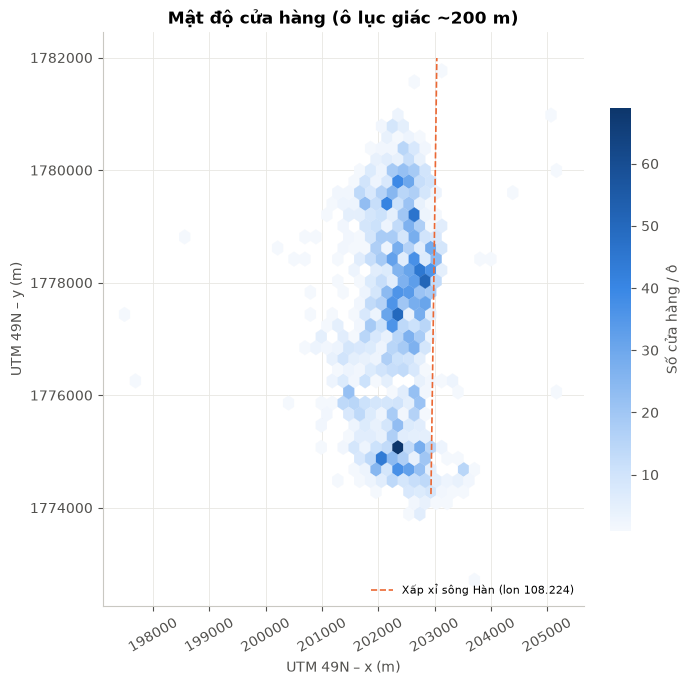

Khoảng cách tới sông (xấp xỉ): trung vị 608 m | 40.4% cửa hàng trong 500 m | phía Đông sông (lon > 108.224): 3.9%


In [14]:
# Bản đồ tĩnh cho báo cáo: mật độ hexbin (UTM, mét)
xy = geo.to_utm(df)
fig, ax = plt.subplots(figsize=(7, 8))
hb = ax.hexbin(xy[:, 0], xy[:, 1], gridsize=40, cmap=viz.SEQ_CMAP, mincnt=1, linewidths=0.2)
ax.set_aspect("equal")
ax.set_title("Mật độ cửa hàng (ô lục giác ~200 m)")
ax.set_xlabel("UTM 49N – x (m)"); ax.set_ylabel("UTM 49N – y (m)")
river_x = geo.to_utm(pd.DataFrame({"latitude": [16.03, 16.10], "longitude": [geo.RIVER_LON] * 2}))
ax.plot(river_x[:, 0], river_x[:, 1], ls="--", color=viz.PALETTE[1], lw=1.2, label="Xấp xỉ sông Hàn (lon 108.224)")
ax.legend(loc="lower right", fontsize=8)
cb = plt.colorbar(hb, ax=ax, fraction=0.04); cb.set_label("Số cửa hàng / ô"); cb.outline.set_visible(False)
ax.ticklabel_format(useOffset=False, style="plain"); ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); viz.save_fig(fig, "02_density_hexbin"); plt.show()
d = geo.dist_to_river_m(df["latitude"], df["longitude"])
print(f"Khoảng cách tới sông (xấp xỉ): trung vị {np.median(d):.0f} m | {np.mean(d < 500):.1%} cửa hàng trong 500 m | "
      f"phía Đông sông (lon > {geo.RIVER_LON}): {(df['longitude'] > geo.RIVER_LON).mean():.1%}")

## 7. Nhận xét (insight)

Các con số dưới đây lấy từ output đã chạy ở trên.

1. **Thị trường tập trung vào đồ uống và món nước.** Ba nhóm Cà phê & nước (21,4%), Bún/Phở/Cháo (18,3%) và Ăn vặt & Bánh mì (15,3%) chiếm khoảng 55% số cửa hàng.
   FOOD áp đảo SHOP với tỉ lệ khoảng 12,8 : 1. Chỉ 18,4% cửa hàng có từ 2 nhãn loại hình trở lên.
2. **Phân bố không gian kéo dài theo trục Bắc–Nam, nằm phía Tây sông Hàn.** 40,4% cửa hàng cách đường xấp xỉ sông dưới 500 m. Bản đồ mật độ cho thấy **hai cực**:
   - cực phía Bắc ở khu trung tâm cũ (Hải Châu 1, Thạch Thang, Phước Ninh);
   - cực phía Nam ở Hòa Cường Bắc/Nam, với ô lục giác dày nhất khoảng 65 cửa hàng;
   - giữa hai cực là một dải thưa hơn.
3. **Cửa hàng tập trung trên một số ít tuyến đường.** 10/318 tuyến đường chứa 37,4% số cửa hàng có tên đường. Dẫn đầu là Hoàng Diệu (189), Núi Thành (146), Trưng Nữ Vương (142), Đống Đa (121) và Lê Thanh Nghị (115).
4. **Cơ cấu loại hình phụ thuộc vào vị trí.** Kiểm định Chi-square cho thấy phường và loại hình không độc lập (p ≈ 6e-8). Lưu ý một số ô có tần số kỳ vọng nhỏ nên p chỉ mang tính tham khảo. Cụ thể:
   - Khu trung tâm (Phước Ninh, Hải Châu 1, Thạch Thang) có tỉ lệ cà phê 27–28%, so với 11–13% ở Bình Hiên và Hải Châu 2.
   - Bình Hiên nghiêng về Cơm và Bún/Phở.
   - Hải Châu 2 có 13% là cửa hàng thực phẩm, gắn với chợ Cồn.
   - Hòa Cường Nam gần như không có cửa hàng tráng miệng (1 cửa hàng).

   Đây là **căn cứ trực tiếp cho bài toán dự đoán loại hình theo vị trí** ở notebook 05.
5. **Rating khác nhau có ý nghĩa thống kê giữa các nhóm loại hình (Kruskal–Wallis, p ≈ 2e-24), nhưng chênh lệch tuyệt đối nhỏ.**
   - Lẩu & Nướng cao nhất: trung bình 4,25, và có tỉ lệ được đánh giá cao nhất (65%).
   - Cửa hàng thực phẩm thấp nhất: trung bình 3,80, chỉ 22,4% có đánh giá.
   - Theo phường, khu trung tâm cao hơn (Hải Châu 1: 4,20; Phước Ninh: 4,18) so với Bình Thuận (4,04). Chênh lệch giữa các phường chỉ khoảng 0,16 điểm.
6. **Chuỗi chiếm 22% số cửa hàng nhưng không được đánh giá cao hơn.** Rating trung bình của chain là 4,07, của quán độc lập là 4,13 (Mann–Whitney p ≈ 3e-5). Tỉ lệ chain cao nhất ở Cửa hàng thực phẩm (33,6%) và Tráng miệng (29,2%), thấp nhất ở Lẩu & Nướng (15,4%).
7. **Chỉ khoảng một nửa (51,8%) cửa hàng có rating.** Nếu dùng rating làm biến mục tiêu thì mất một nửa dữ liệu và còn phụ thuộc vào giả định về `flag`. Đây là thêm một lý do để notebook 05 chọn **dự đoán loại hình** (dùng được toàn bộ cửa hàng) thay vì dự đoán rating.